In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold,
    cross_val_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
print("Libraries imported and dataset loaded successfully!")
df=pd.read_csv(r"C:\Users\91741\Desktop\Crop-Recommendation-MLOps\Crop_recommendation.csv.zip")

Libraries imported and dataset loaded successfully!


1.Install the Python libraries required for the project.
  These libraries are used for:
- Model evaluation
- Saving and loading the trained model


2.Importing Libraries
- Pandas and NumPy are used for data processing.
- Matplotlib and Seaborn are used for visualization

3. Loading the Dataset
- Load the Crop Recommendation dataset into a Pandas DataFrame.
- The dataset contains soil and environmental conditions.
- The target variable represents the crop recommended for those conditions.

In [2]:

df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


The first five rows of the dataset are displayed below to get a quick overview of the available data.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB


This step helps us understand the overall structure and quality of the dataset before starting the analysis. It shows how many records are available and what columns are included in the dataset. It also tells us the data type of each column, which helps identify numerical and categorical features. Finally, it checks whether any columns contain missing values. This gives us a clear idea of whether the dataset is ready for further preprocessing and model building.

In [4]:

df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


This step gives us a statistical summary of the numerical features in the dataset. It shows important values such as the count, mean, standard deviation, minimum, and maximum. It also includes the 25th, 50th, and 75th percentile values, which help us understand how the data is distributed. This gives us a quick idea about the range and variation of soil and environmental conditions.

In [5]:
print("Columns:")
print(df.columns.tolist())

Columns:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']


This step displays all the column names available in the dataset. It helps us understand what information is present and identify the features that can be used for crop recommendation.

In [6]:
print("Missing values in each column:\n")
print(df.isnull().sum())
print(
    "\nTotal missing values:",
    df.isnull().sum().sum()
)

Missing values in each column:

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Total missing values: 0


Checking for missing values because incomplete data can affect model training.If missing values are present, we would need to handle them before training.
This step checks each column to see if any data is missing and also calculates the total number of missing values in the dataset. This helps us make sure the data is complete before moving on to the next steps.

In [7]:
print(
    "Number of duplicate rows:",
    df.duplicated().sum()
)

Number of duplicate rows: 0


This step checks the dataset for any duplicate rows. It counts how many rows contain exactly the same information as another row. Identifying duplicates is important because repeated records can affect the analysis and may influence the model's performance. If duplicates are found, they can be removed before moving to the next stage.

In [8]:
print(
    "Number of crop classes:",
    df["label"].nunique()
)
print("\nCrop classes:")
print(
    df["label"].unique()
)

Number of crop classes: 22

Crop classes:
<StringArray>
[       'rice',       'maize',    'chickpea', 'kidneybeans',  'pigeonpeas',
   'mothbeans',    'mungbean',   'blackgram',      'lentil', 'pomegranate',
      'banana',       'mango',      'grapes',  'watermelon',   'muskmelon',
       'apple',      'orange',      'papaya',     'coconut',      'cotton',
        'jute',      'coffee']
Length: 22, dtype: str


This step identifies how many different crop classes are present in the dataset. It also displays the names of all the available crops that the model can learn to predict. This helps us understand the range of crop recommendations covered by the dataset. It also confirms that the target column contains multiple crop categories for classification.

In [9]:
crop_counts = df["label"].value_counts()
print(crop_counts)

label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


Counting how many samples are available for each crop.This helps us understand whether the dataset is reasonably balanced across the different crop categories.

In [10]:
features = [
    "N",
    "P",
    "K",
    "temperature",
    "humidity",
    "ph",
    "rainfall"
]
target = "label"
print("Features:", features)
print("Target:", target)

Features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Target: label


This step defines the input features that will be used by the machine learning model for crop recommendation. The features include soil nutrients such as N, P, and K, along with temperature, humidity, pH, and rainfall. The label column is selected as the target because it represents the crop that the model needs to predict. This clearly separates the information used for prediction from the final crop recommendation.

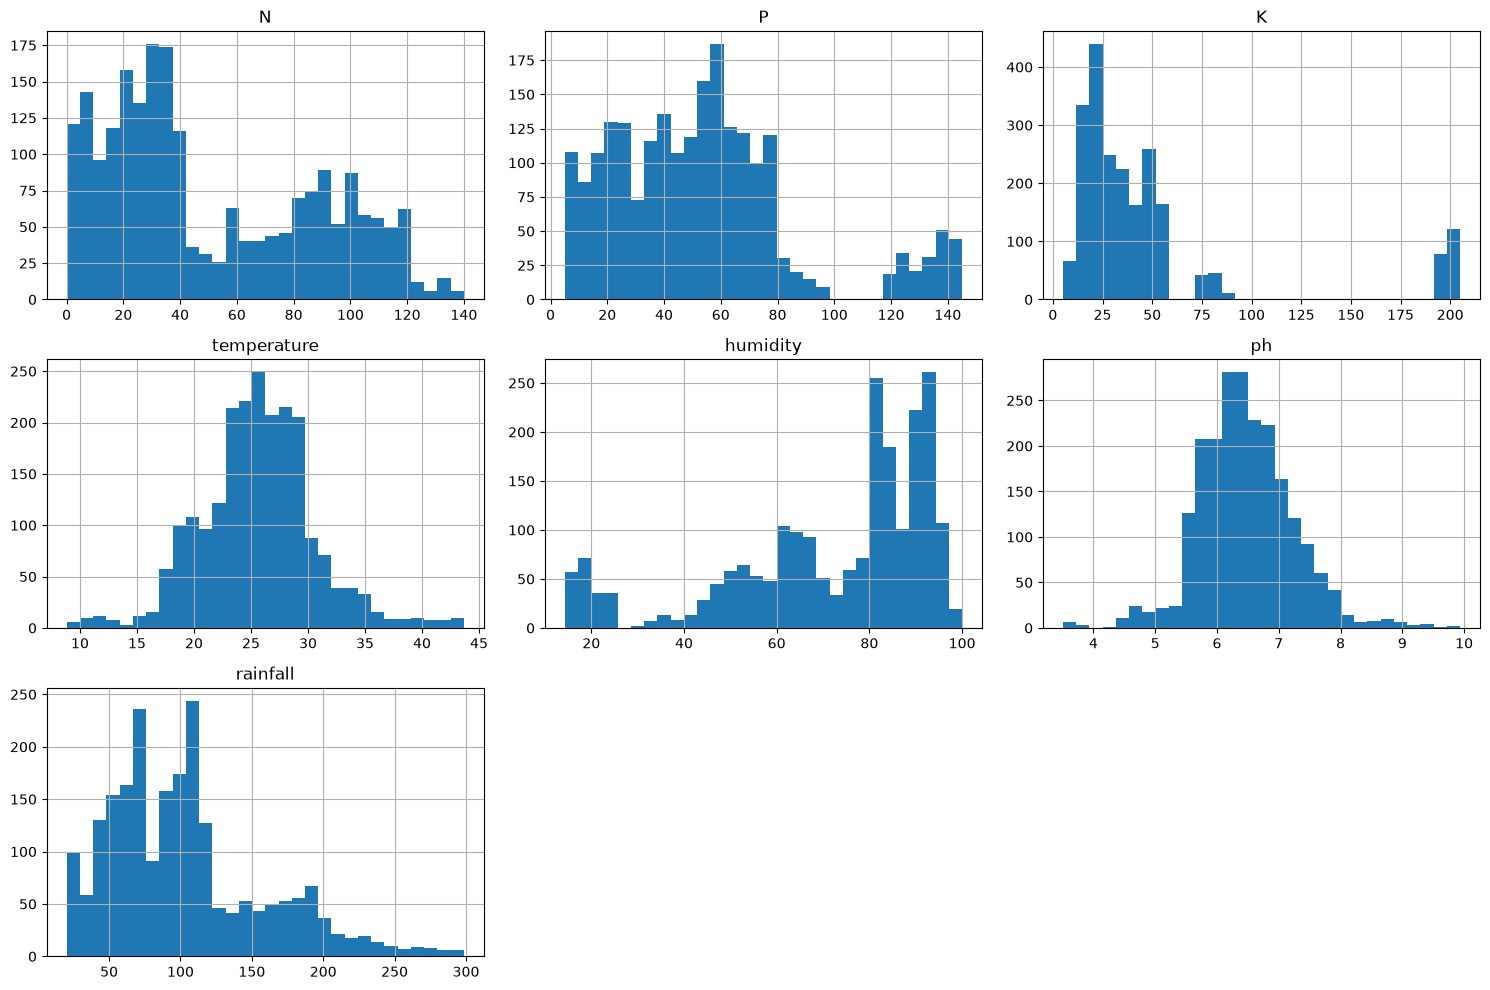

In [11]:
df[features].hist(
    figsize=(15, 10),
    bins=30
)
plt.tight_layout()
plt.show()

creates histograms for the selected features to understand how their values are distributed. It displays all the histograms together in a larger figure, making them easier to compare. The bins=30 setting divides the data into 30 groups. plt.tight_layout() keeps the graphs neatly arranged without overlapping.

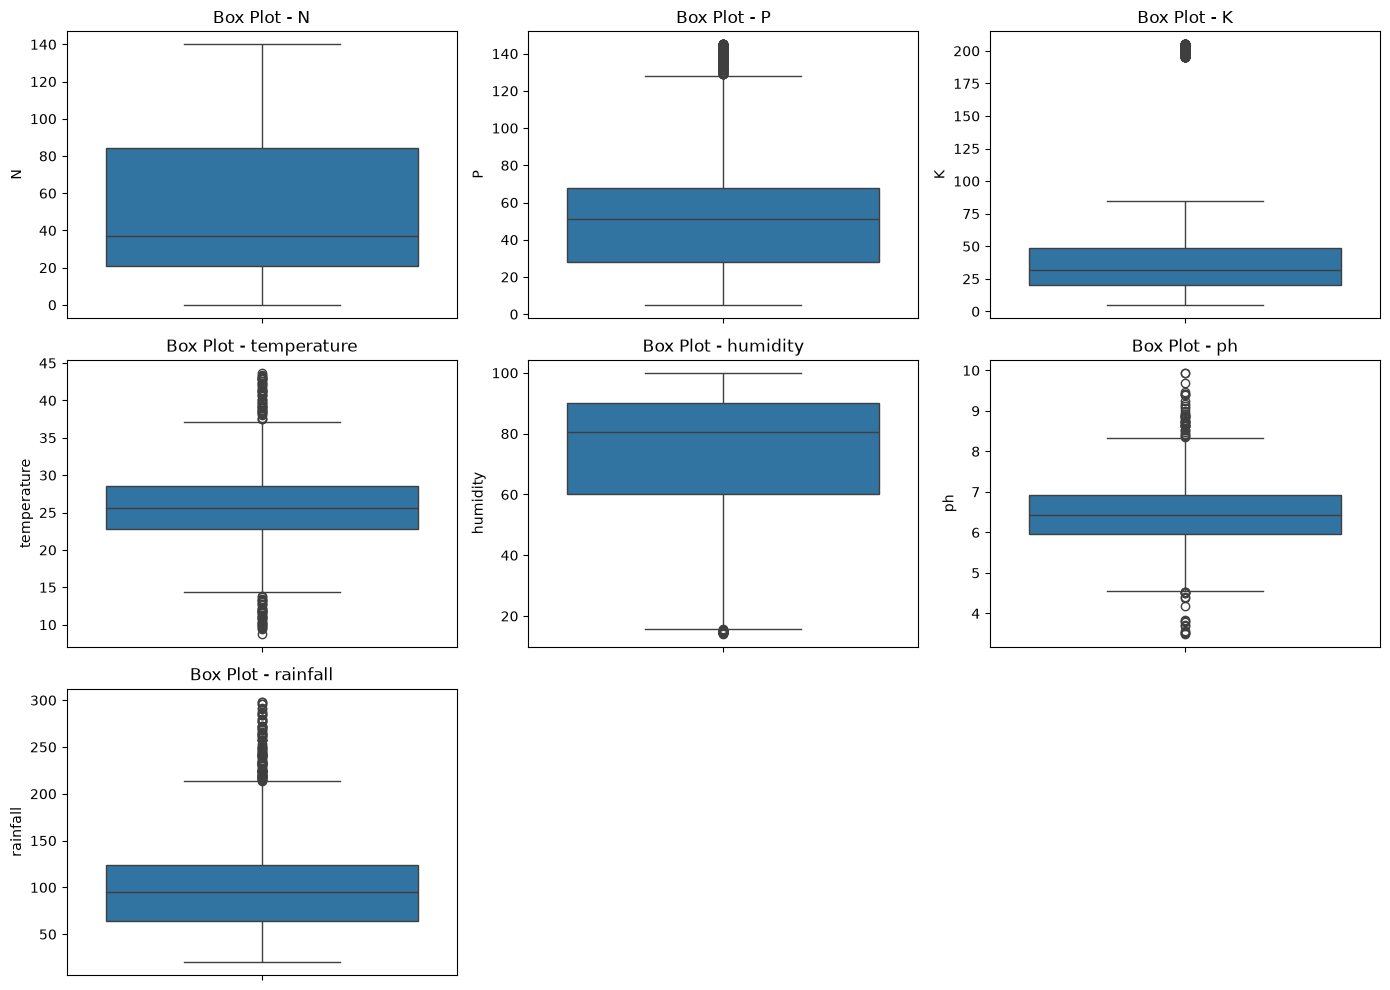

In [12]:
plt.figure(figsize=(14, 10))

for i, feature in enumerate(features, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[feature])
    plt.title(f"Box Plot - {feature}")
    plt.ylabel(feature)

plt.tight_layout()
plt.show()

Boxplots are created for the selected features to understand their distribution and identify possible outliers. Rotating the feature names makes the chart easier to read. It shows the median, overall range, and possible outliers in the data. The black dots seen outside the boxes represent outliers, which are values that are unusually far from the normal range

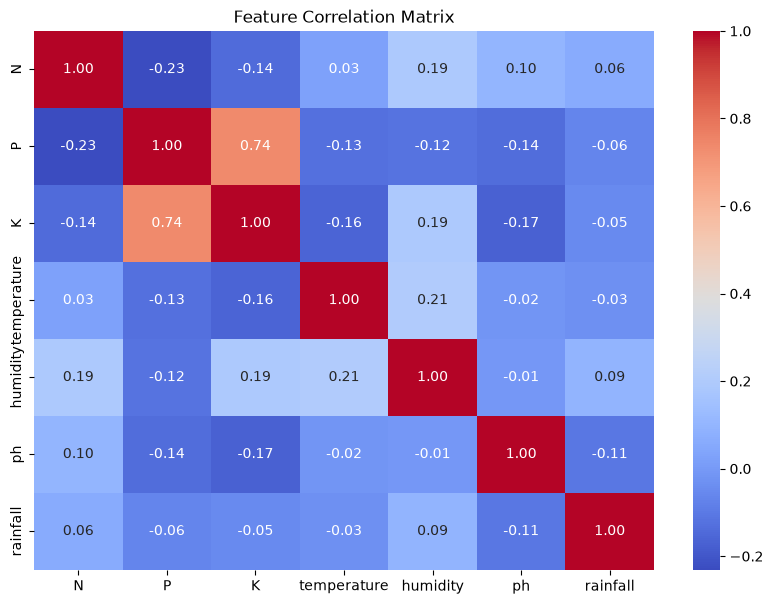

In [13]:
plt.figure(figsize=(10, 7))
sns.heatmap(
    df[features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Feature Correlation Matrix")
plt.show()

To understand how the different features are related to each other, I created a correlation matrix.  
The heatmap makes it easy to identify whether two features have a **positive, negative, or weak correlation**.

- Values close to **+1** indicate a strong positive relationship.
- Values close to **-1** indicate a strong negative relationship.
- Values close to **0** indicate little or no linear relationship.

The color scale helps us quickly identify stronger correlations between the features.

In [14]:
X = df[features]
y = df[target]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2200, 7)
y shape: (2200,)


- `X` contains all the selected features used as inputs to the model.
- `y` contains the target column that we want the model to predict.
- Finally, I checked the shape of both `X` and `y` to make sure the data was separated correctly.

In [15]:
X.head()

,N,P,K,temperature,humidity,ph,rainfall
0,90,42,43,20.879744,82.002744,6.502985,202.935536
1,85,58,41,21.770462,80.319644,7.038096,226.655537
2,60,55,44,23.004459,82.320763,7.840207,263.964248
3,74,35,40,26.491096,80.158363,6.980401,242.864034
4,78,42,42,20.130175,81.604873,7.628473,262.717340


After separating the input features (X) from the target variable (y), X.head() is used to display the first five rows of the feature dataset. This helps us check whether the features have been selected correctly. It also gives a quick look at the data values before moving on to the next steps of the analysis.

In [16]:
y.head()

0    rice
1    rice
2    rice
3    rice
4    rice
Name: label, dtype: str

After separating the target variable (y) from the input features (X), y.head() is used to display the first five values of the target variable. This helps us check the target data and make sure it has been separated correctly. It also gives a quick view of the values that the model will try to predict.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print(
    "Training data:",
    X_train.shape
)
print(
    "Testing data:",
    X_test.shape
)

Training data: (1760, 7)
Testing data: (440, 7)


Here, I divided the dataset into training data and testing data using train_test_split().

- 80% of the data is used for training the model.
- 20% is kept aside for testing the model.
- random_state=42 ensures that the same split is obtained each time.
- stratify=y keeps the target classes distributed proportionally in both training and testing data.


In [18]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_test)

logistic_accuracy = accuracy_score(
    y_test,
    logistic_pred
)

print("Logistic Regression Accuracy:", logistic_accuracy)

Logistic Regression Accuracy: 0.9727272727272728


This code builds a Logistic Regression model using a pipeline that first standardizes the input features and then applies the classifier. The model is trained using the training data and then used to predict the classes for the test data. Finally, the predictions are compared with the actual test values to calculate the model’s accuracy. The printed accuracy shows how well the Logistic Regression model performs on the test data.

In [19]:
svm_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),

    (
        "classifier",
        SVC(
            kernel="rbf",
            C=10,
            probability=True,
            random_state=42
        )
    )
])

svm_model.fit(
    X_train,
    y_train
)

svm_pred = svm_model.predict(
    X_test
)

svm_accuracy = accuracy_score(
    y_test,
    svm_pred
)

print(
    "SVM Accuracy:",
    svm_accuracy
)

SVM Accuracy: 0.9886363636363636


Training the SVM Model
Here, I created an SVM model using a pipeline.First, StandardScaler scales the features to a similar range. Then, the SVM classifier with an RBF kernel is used to learn the patterns in the training data.After training, the model predicts the classes for the test data. Finally, I calculated the accuracy score to check how well the SVM model performs on unseen data.

In [20]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

rf_pred = rf_model.predict(
    X_test
)

rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)
print(
    "Random Forest Accuracy:",
    rf_accuracy
)

Random Forest Accuracy: 0.9931818181818182


Training the Random Forest Model
Here, I created a Random Forest classifier with 300 decision trees.The model learns from the training data and combines the predictions from multiple trees to make the final prediction. After training, I used the model to predict the classes in the test data.Finally, I calculated the accuracy score to check how well the Random Forest model performs on unseen data.

In [21]:
from sklearn.model_selection import train_test_split

X = df[features]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [22]:
param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"]
}

print("Parameter grid created successfully!")

Parameter grid created successfully!


Setting Parameters for Random Forest Tuning
A parameter grid is created with different combinations of Random Forest settings.These parameters control how the trees are built and help find the best-performing model.
The grid includes the number of trees, maximum tree depth, minimum samples required for splitting and leaf nodes, and the number of features considered at each split.
This parameter grid will be used for hyperparameter tuning.

In [23]:
from sklearn.model_selection import GridSearchCV
rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

print("Hyperparameter tuning started...")

grid_search.fit(
    X_train,
    y_train
)

print("Hyperparameter tuning completed!")

Hyperparameter tuning started...
Fitting 5 folds for each of 96 candidates, totalling 480 fits
Hyperparameter tuning completed!


Hyperparameter Tuning with Grid Search
GridSearchCV is used to test different combinations of Random Forest parameters.The model uses 5-fold cross-validation to evaluate each combination and selects the settings that provide the best accuracy.After completing the search, the best parameter combination can be used to build a better-performing Random Forest model.

In [24]:
print("Best Parameters:")
print(
    grid_search.best_params_
)

Best Parameters:
{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}


Best Random Forest Parameters
The best parameter combination found during hyperparameter tuning is displayed using `grid_search.best_params_`.These parameters produced the highest accuracy during the 5-fold cross-validation process and can be used for the final Random Forest model.

In [25]:
print(
    "Best Cross-Validation Accuracy:"
)
print(
    f"{grid_search.best_score_:.4f}"
)

Best Cross-Validation Accuracy:
0.9960


Best Cross-Validation Accuracy
The highest accuracy achieved during the 5-fold cross-validation process is displayed.The accuracy is formatted to four decimal places, making it easier to read and compare with other model results.

In [26]:
best_model = grid_search.best_estimator_
print("Best Random Forest Model:")
print(best_model)

Best Random Forest Model:
RandomForestClassifier(max_depth=10, min_samples_split=5, n_estimators=200,
                       n_jobs=-1, random_state=42)


In [27]:
# Calculate training accuracy
train_predictions = best_model.predict(X_train)
train_accuracy = accuracy_score(y_train, train_predictions)
print("Training Accuracy:", train_accuracy)

Training Accuracy: 0.9965909090909091


In [28]:
final_pred = best_model.predict(
    X_test
)

final_accuracy = accuracy_score(
    y_test,
    final_pred
)

print(
    f"Final Test Accuracy: {final_accuracy:.4f}"
)

Final Test Accuracy: 0.9932


Evaluating the Final Model
The tuned Random Forest model is used to make predictions on the test data.The predicted values are compared with the actual target values using the accuracy score.
The final test accuracy shows how well the tuned model performs on unseen data.

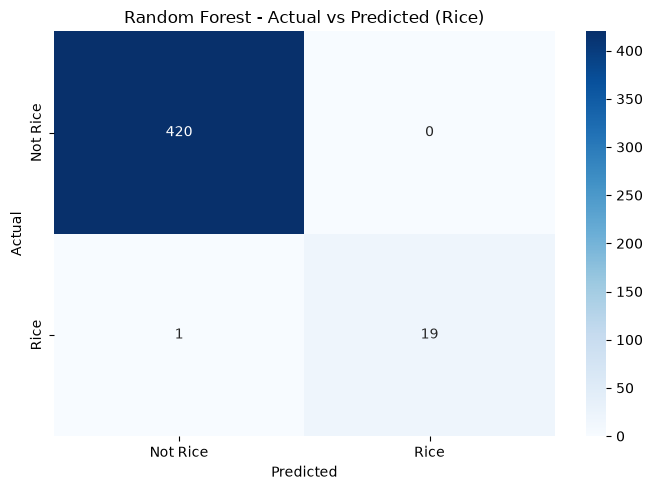

In [29]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Random Forest predictions
rf_pred = best_model.predict(X_test)

# Convert to binary: Rice = 1, Other crops = 0
actual = (y_test == "rice").astype(int)
predicted = (rf_pred == "rice").astype(int)

# Confusion matrix
cm = confusion_matrix(actual, predicted)

# Plot 4-box confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Rice", "Rice"],
    yticklabels=["Not Rice", "Rice"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Actual vs Predicted (Rice)")
plt.tight_layout()
plt.show()

Selecting the Best Random Forest Model
The best Random Forest model identified during Grid Search is stored in `best_model`.This model contains the parameter combination that achieved the highest cross-validation accuracy and will be used for further evaluation on the test data.

In [30]:
precision = precision_score(
    y_test,
    final_pred,
    average="weighted"
)

recall = recall_score(
    y_test,
    final_pred,
    average="weighted"
)

f1 = f1_score(
    y_test,
    final_pred,
    average="weighted"
)

print(f"Accuracy  : {final_accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

Accuracy  : 0.9932
Precision : 0.9935
Recall    : 0.9932
F1 Score  : 0.9932


Model Performance Evaluation
Accuracy, precision, recall, and F1 score are calculated to get a complete view of the model's performance.
- Accuracy shows the overall percentage of correct predictions.
- Precision shows how many of the predicted classes were actually correct.
- Recall shows how well the model identifies the actual classes.
- F1 Score provides a balance between precision and recall.
Weighted averaging is used so that the contribution of each class is considered based on its number of samples.

In [31]:
print(
    classification_report(
        y_test,
        final_pred
    )
)

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      0.95      0.97        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.95      1.00      0.98        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

Classification Report
The classification report provides a detailed summary of the model's performance for each class.It displays precision, recall, F1 score, and support for every class, making it easier to understand how well the model performs across different categories.

In [32]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    best_model,
    X,
    y,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Cross Validation Scores:")
print(cv_scores)

print(
    "\nMean CV Accuracy:",
    f"{cv_scores.mean():.4f}"
)

print(
    "Standard Deviation:",
    f"{cv_scores.std():.4f}"
)

Cross Validation Scores:
[0.99318182 0.99545455 1.         0.99545455 0.99318182]

Mean CV Accuracy: 0.9955
Standard Deviation: 0.0025


Cross-Validation Evaluation
Stratified 5-fold cross-validation is used to check how consistently the model performs across different parts of the dataset.
The data is divided into 5 folds, while maintaining a similar distribution of target classes in each fold.
The accuracy score is calculated for each fold. The mean CV accuracy shows the overall performance, while the standard deviation indicates how much the results vary between the folds.

In [33]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": best_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
4,humidity,0.217214
6,rainfall,0.215909
2,K,0.184667
1,P,0.152680
0,N,0.102918
3,temperature,0.075110
5,ph,0.051503


Feature Importance
The importance of each feature is calculated using the best Random Forest model.
The features are arranged from highest to lowest importance so it is easy to identify which inputs contribute the most to the model's predictions.
A higher importance value means that the feature has a greater influence on the model's decision-making.

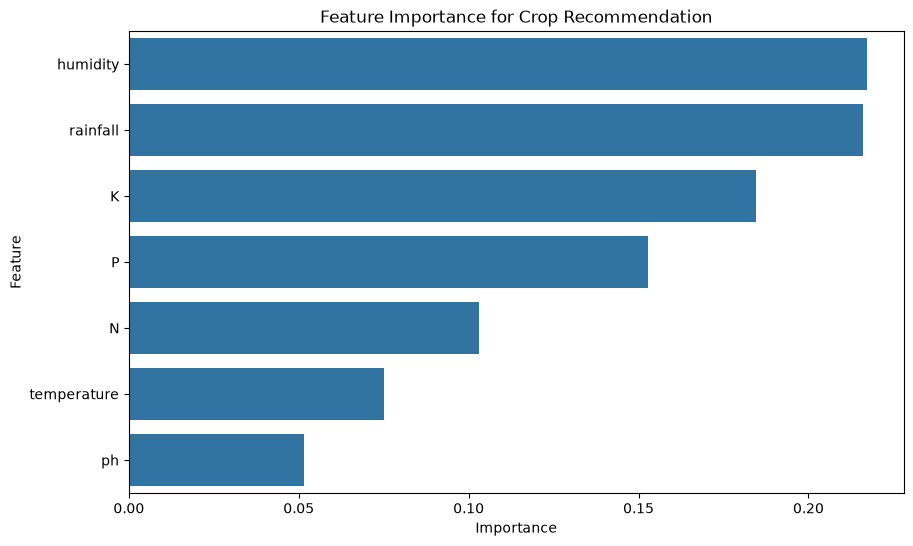

In [34]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title(
    "Feature Importance for Crop Recommendation"
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

This bar chart visually represents the importance of each feature in the crop recommendation model. The length of each bar shows how much influence that feature has on the model’s predictions. Features with longer bars are more important compared to those with shorter bars. The chart makes it easier to compare the contribution of different features. Overall, it helps us understand which factors are most useful for recommending crops.

In [35]:
os.makedirs(
    "models",
    exist_ok=True
)

print("Models folder created!")

Models folder created!


This code creates a folder named “models” to store the trained machine learning models. The exist_ok=True option makes sure that no error occurs if the folder already exists. It is useful for organizing and saving the models created during the project. Finally, the print() statement confirms that the folder has been created successfully.

In [36]:
joblib.dump(
    features,
    "models/features.pkl"
)

print(
    "Feature names saved successfully!"
)

Feature names saved successfully!


This code saves the trained best model as a .pkl file using joblib. The model is stored inside the models folder with the name crop_recommendation_model.pkl. Saving the model allows us to use it later without training it again. Finally, the print() statement confirms that the model was saved successfully.

In [37]:
sample = pd.DataFrame({
    "N": [90],
    "P": [4],
    "K": [3],
    "temperature": [20.8],
    "humidity": [8.0],
    "ph": [6.5],
    "rainfall": [22.9]
})
sample

,N,P,K,temperature,humidity,ph,rainfall
0,90,4,3,20.8,8.0,6.5,22.9


Creating a Sample Input
A sample dataset is created with values for nitrogen, phosphorus, potassium, temperature, humidity, pH, and rainfall.This sample input will be used to test the trained model and generate a crop recommendation based on the given conditions.

In [38]:
# Predict the recommended crop
prediction = best_model.predict(sample)
print("Recommended Crop:", prediction[0])

Recommended Crop: muskmelon


In [39]:
import random
sample = pd.DataFrame({
    "N": [random.randint(0, 140)],
    "P": [random.randint(5, 145)],
    "K": [random.randint(5, 205)],
    "temperature": [round(random.uniform(10, 40), 1)],
    "humidity": [round(random.uniform(40, 100), 1)],
    "ph": [round(random.uniform(3.5, 9.5), 1)],
    "rainfall": [round(random.uniform(20, 300), 1)]
})
# Display randomly generated input
print("Randomly Selected Input:")
print(sample)
# Predict crop
prediction = best_model.predict(sample)
print("\nRecommended Crop:", prediction[0])

Randomly Selected Input:
    N   P    K  temperature  humidity   ph  rainfall
0  78  86  136         28.2      48.4  6.8      28.7



Recommended Crop: muskmelon


In [40]:
import joblib

loaded_model = joblib.load(
    "models/crop_recommendation_model.pkl"
)

print("Saved model loaded successfully!")

FileNotFoundError: [Errno 2] No such file or directory: 'models/crop_recommendation_model.pkl'

In [ ]:
prediction = loaded_model.predict(
    sample
)

print(
    " Recommended Crop:",
    prediction[0]
)

 Recommended Crop: coffee


This code uses the saved model to predict a crop for the given sample input. The loaded_model.predict() function takes the sample data and generates the predicted crop. The result is stored in prediction, and prediction[0] gets the first predicted value. Finally, the print() statement displays the recommended crop.

In [ ]:
final_pred = best_model.predict(
    X_test
)

In [ ]:
# Enter the values provided by the user

N = 9
P = 9
K = 4
temperature = 20.8
humidity = 8.0
ph = 6.5
rainfall = 20.9

user_input = pd.DataFrame({
    "N": [N],
    "P": [P],
    "K": [K],
    "temperature": [temperature],
    "humidity": [humidity],
    "ph": [ph],
    "rainfall": [rainfall]
})

# Predict the recommended crop
prediction = rf_model.predict(user_input)

print("Recommended Crop:", prediction[0])

Recommended Crop: kidneybeans


In [ ]:
probabilities = loaded_model.predict_proba(
    sample
)[0]

classes = loaded_model.classes_

probability_df = pd.DataFrame({
    "Crop": classes,
    "Probability": probabilities
})

probability_df = probability_df.sort_values(
    by="Probability",
    ascending=False
)

probability_df.head(10)

,Crop,Probability
5,coffee,0.280161
3,chickpea,0.223500
20,rice,0.114302
8,jute,0.109402
1,banana,0.079762
11,maize,0.071500
17,papaya,0.026494
7,grapes,0.025000
0,apple,0.025000
18,pigeonpeas,0.020000


Crop Prediction Probabilities
The trained model is used to calculate the probability of each crop for the given sample input.
The crop classes and their corresponding probabilities are stored in a DataFrame and arranged from highest to lowest probability.
The top 10 crops with the highest predicted probabilities are displayed to identify the most suitable recommendations.

In [ ]:
os.makedirs(
    "reports",
    exist_ok=True
)

metrics = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "Mean CV Accuracy"
    ],

    "Score": [
        final_accuracy,
        precision,
        recall,
        f1,
        cv_scores.mean()
    ]
})

metrics.to_csv(
    "reports/model_metrics.csv",
    index=False
)

print(
    "Model metrics saved successfully!"
)

Model metrics saved successfully!


This code creates a reports folder to store the model evaluation results. It collects important performance measures such as accuracy, precision, recall, F1 score, and mean cross-validation accuracy into a table. The table is then saved as a CSV file named model_metrics.csv inside the reports folder. This makes it easy to store and review the model’s performance later. Finally, the message confirms that the metrics were saved successfully.

In [ ]:
feature_importance.to_csv(
    "reports/feature_importance.csv",
    index=False
)

print(
    "Feature importance saved successfully!"
)

Feature importance saved successfully!


This code saves the feature importance table as a CSV file inside the reports folder. The index=False option prevents the DataFrame index from being added to the file. This makes it easy to keep the feature importance results for future analysis or reporting. Finally, the print() statement confirms that the file was saved successfully.